# Encoder Training — Contrastive/Triplet Loss

This notebook trains a small head on top of the pretrained OpenL3 embeddings, using window-level embeddings as training examples for a contrastive/triplet loss, following the plan established in the project brief: closed-set pairwise verification given the small number of recordings per cantaor.

Input: window-level OpenL3 embeddings (`data/processed/window_embeddings/`, one `.npy` per recording) and the train/test split (`data/processed/train_test_split.csv`).

In [ ]:
import os

# Notebooks use relative paths — run from the project root (cante-embeddings/).
if not os.path.exists('data/processed'):
    raise RuntimeError("Run this notebook from the project root (cante-embeddings/).")

In [15]:
import numpy as np
import pandas as pd
from pathlib import Path

recordings = pd.read_csv('data/processed/train_test_split.csv')
WINDOWS_DIR = Path('data/processed/window_embeddings')

window_counts = {}
for _, row in recordings.iterrows():
    key = row['recording_id'].rsplit('.', 1)[0]
    windows = np.load(WINDOWS_DIR / f"{key}.npy")
    window_counts[key] = windows.shape[0]

total_windows = sum(window_counts.values())
print(f"Total ventanas disponibles para entrenamiento: {total_windows}")
print(f"Media de ventanas por grabación: {total_windows / len(window_counts):.1f}")

Total ventanas disponibles para entrenamiento: 170693
Media de ventanas por grabación: 1566.0


## Loading windows organized by cantaor (train split only)

To build triplets (anchor, positive, negative), we need windows grouped by cantaor. Only **train-split recordings** are used here - test-split windows are held out entirely for evaluation, never seen during training, preserving the closed-set protocol's integrity.

In [16]:
train_recordings = recordings[recordings['split'] == 'train']

windows_by_cantaor = {}
for _, row in train_recordings.iterrows():
    key = row['recording_id'].rsplit('.', 1)[0]
    windows = np.load(WINDOWS_DIR / f"{key}.npy")
    cantaor = row['norm_name']
    windows_by_cantaor.setdefault(cantaor, []).append(windows)

# Concatenar todas las ventanas de cada cantaor en un solo array
for cantaor in windows_by_cantaor:
    windows_by_cantaor[cantaor] = np.concatenate(windows_by_cantaor[cantaor], axis=0)

cantaores_train = list(windows_by_cantaor.keys())
print(f"Cantaores en train: {len(cantaores_train)}")
print(f"Total ventanas en train: {sum(w.shape[0] for w in windows_by_cantaor.values())}")
print()
print("Ventanas por cantaor (primeros 5):")
for c in cantaores_train[:5]:
    print(f"  {c}: {windows_by_cantaor[c].shape[0]}")

Cantaores en train: 31
Total ventanas en train: 122642

Ventanas por cantaor (primeros 5):
  fernandoterremoto: 12257
  manuelsotosordera: 10846
  fosforito: 5698
  pacotoronjo: 1791
  antoniomairena: 18440


## Triplet sampling strategy

Given the large imbalance in windows per cantaor (e.g. Antonio Mairena: 18,440 vs. some cantaores with far fewer), triplets are sampled by first choosing cantaores **uniformly** (anchor and negative), then sampling a window within each - this prevents cantaores with more recordings from dominating training simply by volume.

In [17]:
import random

def sample_triplet(windows_by_cantaor, cantaores, rng):
    anchor_cantaor, negative_cantaor = rng.sample(cantaores, 2)

    anchor_windows = windows_by_cantaor[anchor_cantaor]
    negative_windows = windows_by_cantaor[negative_cantaor]

    # anchor y positive: dos ventanas distintas del mismo cantaor
    idx_a, idx_p = rng.sample(range(len(anchor_windows)), 2) if len(anchor_windows) >= 2 else (0, 0)
    idx_n = rng.randrange(len(negative_windows))

    return anchor_windows[idx_a], anchor_windows[idx_p], negative_windows[idx_n]

rng = random.Random(42)

# Prueba: generar 3 triplets de ejemplo
for _ in range(3):
    a, p, n = sample_triplet(windows_by_cantaor, cantaores_train, rng)
    print(f"anchor shape: {a.shape}, positive shape: {p.shape}, negative shape: {n.shape}")

anchor shape: (512,), positive shape: (512,), negative shape: (512,)
anchor shape: (512,), positive shape: (512,), negative shape: (512,)
anchor shape: (512,), positive shape: (512,), negative shape: (512,)


## The projection head

A small feedforward network projects the 512-d OpenL3 embedding into a lower-dimensional space optimized specifically for cantaor verification, trained with triplet loss. OpenL3's weights are frozen (not fine-tuned). Only this small head is trained, which is appropriate given the very limited training data.

In [18]:
import torch
import torch.nn as nn
import torch.nn.functional as F

print(torch.__version__)

2.13.0


In [19]:
class ProjectionHead(nn.Module):
    def __init__(self, input_dim=512, hidden_dim=256, output_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, output_dim)
        )

    def forward(self, x):
        out = self.net(x)
        return F.normalize(out, p=2, dim=-1)  # normalizar a norma 1, estándar en metric learning

model = ProjectionHead()
print(model)

# Prueba rápida con un batch falso
test_input = torch.randn(4, 512)
test_output = model(test_input)
print(f"\nInput shape: {test_input.shape}, Output shape: {test_output.shape}")
print(f"Norma de cada vector de salida (debería ser ~1.0): {test_output.norm(dim=-1)}")

ProjectionHead(
  (net): Sequential(
    (0): Linear(in_features=512, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
  )
)

Input shape: torch.Size([4, 512]), Output shape: torch.Size([4, 128])
Norma de cada vector de salida (debería ser ~1.0): tensor([1.0000, 1.0000, 1.0000, 1.0000], grad_fn=<LinalgVectorNormBackward0>)


## Triplet loss and training loop

We use PyTorch's built-in `TripletMarginLoss`, which pushes anchor-positive distance down and anchor-negative distance up, with a margin enforcing a minimum separation. Given the dataset size, training runs for a modest number of steps with periodic loss reporting - this is a small model on a small dataset, not expected to need many epochs.

In [20]:
triplet_loss_fn = nn.TripletMarginLoss(margin=0.3, p=2)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

def sample_batch(batch_size, windows_by_cantaor, cantaores, rng):
    anchors, positives, negatives = [], [], []
    for _ in range(batch_size):
        a, p, n = sample_triplet(windows_by_cantaor, cantaores, rng)
        anchors.append(a)
        positives.append(p)
        negatives.append(n)
    return (torch.tensor(np.stack(anchors), dtype=torch.float32),
            torch.tensor(np.stack(positives), dtype=torch.float32),
            torch.tensor(np.stack(negatives), dtype=torch.float32))

n_steps = 500
batch_size = 32
rng = random.Random(42)

losses = []
for step in range(n_steps):
    anchors, positives, negatives = sample_batch(batch_size, windows_by_cantaor, cantaores_train, rng)

    optimizer.zero_grad()
    emb_a = model(anchors)
    emb_p = model(positives)
    emb_n = model(negatives)

    loss = triplet_loss_fn(emb_a, emb_p, emb_n)
    loss.backward()
    optimizer.step()

    losses.append(loss.item())

    if (step + 1) % 50 == 0:
        avg_loss = sum(losses[-50:]) / 50
        print(f"Step {step + 1}/{n_steps} — avg loss (last 50): {avg_loss:.4f}")

print("\nEntrenamiento completo.")

Step 50/500 — avg loss (last 50): 0.1310
Step 100/500 — avg loss (last 50): 0.1027
Step 150/500 — avg loss (last 50): 0.0875
Step 200/500 — avg loss (last 50): 0.0881
Step 250/500 — avg loss (last 50): 0.0845
Step 300/500 — avg loss (last 50): 0.0798
Step 350/500 — avg loss (last 50): 0.0712
Step 400/500 — avg loss (last 50): 0.0880
Step 450/500 — avg loss (last 50): 0.0732
Step 500/500 — avg loss (last 50): 0.0752

Entrenamiento completo.


## Evaluating the fine-tuned embeddings: UMAP comparison

We compute fine-tuned embeddings for all 109 recordings (mean-pooled over windows, passed through the trained projection head) and visualize with UMAP, using the same layout as the pretrained baseline for direct visual comparison.

In [21]:
model.eval()

finetuned_embeddings = []
with torch.no_grad():
    for _, row in recordings.iterrows():
        key = row['recording_id'].rsplit('.', 1)[0]
        windows = np.load(WINDOWS_DIR / f"{key}.npy")
        windows_tensor = torch.tensor(windows, dtype=torch.float32)
        projected = model(windows_tensor)  # (n_windows, 128)
        recording_emb = projected.mean(dim=0).numpy()  # mean pooling en el espacio proyectado
        finetuned_embeddings.append(recording_emb)

finetuned_matrix = np.stack(finetuned_embeddings)
print(f"Fine-tuned embeddings shape: {finetuned_matrix.shape}")

Fine-tuned embeddings shape: (109, 128)


/Users/lauraortega/Desktop/cante-embeddings/venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


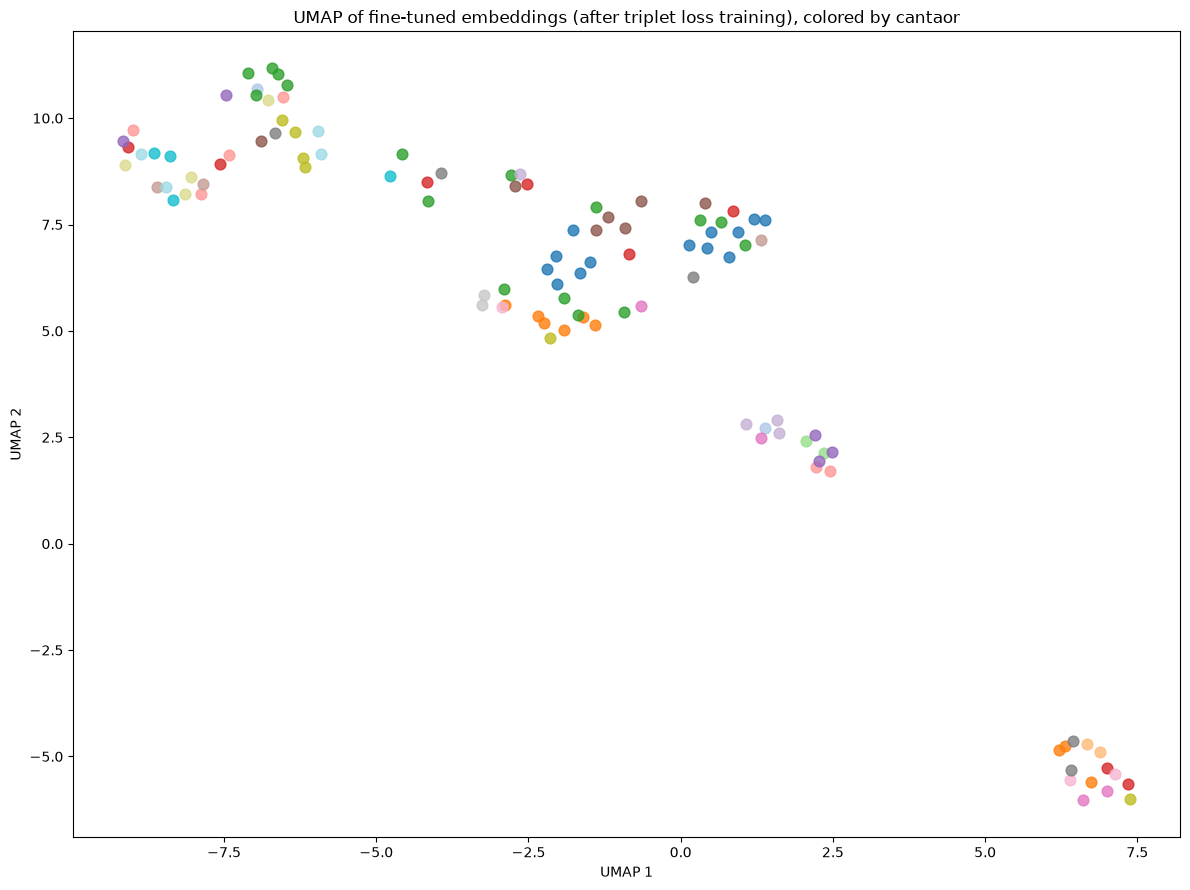

In [22]:
import matplotlib.pyplot as plt
import umap

reducer_ft = umap.UMAP(n_neighbors=10, min_dist=0.3, random_state=42)
embedding_2d_ft = reducer_ft.fit_transform(finetuned_matrix)

fig, ax = plt.subplots(figsize=(12, 9))
norm_names = recordings['norm_name'].values
cantaores = pd.Series(norm_names).unique()
colors = plt.cm.tab20(np.linspace(0, 1, len(cantaores)))
color_map = dict(zip(cantaores, colors))

for cantaor in cantaores:
    mask = norm_names == cantaor
    ax.scatter(embedding_2d_ft[mask, 0], embedding_2d_ft[mask, 1],
               color=color_map[cantaor], s=60, alpha=0.8)

ax.set_title('UMAP of fine-tuned embeddings (after triplet loss training), colored by cantaor')
ax.set_xlabel('UMAP 1')
ax.set_ylabel('UMAP 2')
plt.tight_layout()
plt.savefig('data/processed/umap_finetuned.png', dpi=150)
plt.show()

## Interpretation: before vs. after

Compared to the pretrained baseline (uniform mixing of colors), the fine-tuned embeddings show visibly tighter, more color-coherent groupings for several cantaores. Most notably a compact blue cluster and a looser but visible orange grouping. Other cantaores remain mixed, particularly those with only 1-2 training windows-worth of distinct recordings.

This is consistent with what a small triplet-loss head trained on a small dataset should produce: partial, honest improvement over the pretrained baseline, not full separation. The next step is quantitative evaluation (EER, ROC/AUC) on the held-out test set, which will give a more rigorous measure than visual inspection alone.

## Quantitative evaluation: pairwise verification (EER, ROC/AUC)

For each test recording, we form:
- **Positive pairs**: test recording vs. train recordings of the *same* cantaor.
- **Negative pairs**: test recording vs. train recordings of *different* cantaores.

Distance is measured as cosine distance in the fine-tuned embedding space (embeddings are L2-normalized, so cosine distance is well-behaved). EER is the threshold where false-accept rate equals false-reject rate (lower is better).

In [23]:
from itertools import product

recordings_idx = recordings.reset_index(drop=True)
test_idx = recordings_idx[recordings_idx['split'] == 'test'].index.tolist()
train_idx = recordings_idx[recordings_idx['split'] == 'train'].index.tolist()

pair_distances = []
pair_labels = []  # 1 = mismo cantaor (positivo), 0 = distinto (negativo)

for t_i in test_idx:
    t_emb = finetuned_matrix[t_i]
    t_cantaor = recordings_idx.loc[t_i, 'norm_name']

    for tr_i in train_idx:
        tr_emb = finetuned_matrix[tr_i]
        tr_cantaor = recordings_idx.loc[tr_i, 'norm_name']

        cosine_dist = 1 - np.dot(t_emb, tr_emb)  # embeddings ya normalizados, norma 1
        pair_distances.append(cosine_dist)
        pair_labels.append(1 if t_cantaor == tr_cantaor else 0)

pair_distances = np.array(pair_distances)
pair_labels = np.array(pair_labels)

print(f"Total pares: {len(pair_distances)}")
print(f"Pares positivos (mismo cantaor): {pair_labels.sum()}")
print(f"Pares negativos (distinto cantaor): {(pair_labels == 0).sum()}")

Total pares: 2418
Pares positivos (mismo cantaor): 78
Pares negativos (distinto cantaor): 2340


In [24]:
from sklearn.metrics import roc_curve, roc_auc_score

# Convertimos distancia a "similitud" para que ROC funcione en la dirección esperada (mayor score = más probable positivo)
similarity_scores = -pair_distances

fpr, tpr, thresholds = roc_curve(pair_labels, similarity_scores)
auc = roc_auc_score(pair_labels, similarity_scores)

# EER: el punto donde FPR y FNR (1-TPR) se cruzan
fnr = 1 - tpr
eer_idx = np.nanargmin(np.abs(fpr - fnr))
eer = (fpr[eer_idx] + fnr[eer_idx]) / 2
eer_threshold = -thresholds[eer_idx]  # deshacer el signo para volver a la distancia real

print(f"AUC: {auc:.4f}")
print(f"EER: {eer:.4f} ({eer*100:.1f}%)")
print(f"Umbral de distancia en el punto EER: {eer_threshold:.4f}")

AUC: 0.7481
EER: 0.3402 (34.0%)
Umbral de distancia en el punto EER: 0.1351


## Extended training: does more training help or overfit?

We continue training the same model for more steps, then recompute recording-level embeddings and the EER on the same test pairs, to check whether extended training improves generalization or starts overfitting.

In [25]:
n_extra_steps = 2000
rng2 = random.Random(123)  # semilla distinta para no repetir exactamente los mismos triplets

for step in range(n_extra_steps):
    anchors, positives, negatives = sample_batch(batch_size, windows_by_cantaor, cantaores_train, rng2)

    optimizer.zero_grad()
    emb_a = model(anchors)
    emb_p = model(positives)
    emb_n = model(negatives)

    loss = triplet_loss_fn(emb_a, emb_p, emb_n)
    loss.backward()
    optimizer.step()

    losses.append(loss.item())

    if (step + 1) % 200 == 0:
        avg_loss = sum(losses[-200:]) / 200
        print(f"Extra step {step + 1}/{n_extra_steps} — avg loss (last 200): {avg_loss:.4f}")

print("\nEntrenamiento extendido completo.")

Extra step 200/2000 — avg loss (last 200): 0.0697
Extra step 400/2000 — avg loss (last 200): 0.0691
Extra step 600/2000 — avg loss (last 200): 0.0623
Extra step 800/2000 — avg loss (last 200): 0.0590
Extra step 1000/2000 — avg loss (last 200): 0.0610
Extra step 1200/2000 — avg loss (last 200): 0.0569
Extra step 1400/2000 — avg loss (last 200): 0.0531
Extra step 1600/2000 — avg loss (last 200): 0.0484
Extra step 1800/2000 — avg loss (last 200): 0.0502
Extra step 2000/2000 — avg loss (last 200): 0.0505

Entrenamiento extendido completo.


In [26]:
model.eval()

finetuned_embeddings_v2 = []
with torch.no_grad():
    for _, row in recordings.iterrows():
        key = row['recording_id'].rsplit('.', 1)[0]
        windows = np.load(WINDOWS_DIR / f"{key}.npy")
        windows_tensor = torch.tensor(windows, dtype=torch.float32)
        projected = model(windows_tensor)
        recording_emb = projected.mean(dim=0).numpy()
        finetuned_embeddings_v2.append(recording_emb)

finetuned_matrix_v2 = np.stack(finetuned_embeddings_v2)

# Recalcular pares y EER, mismo procedimiento exacto que antes
pair_distances_v2 = []
pair_labels_v2 = []

for t_i in test_idx:
    t_emb = finetuned_matrix_v2[t_i]
    t_cantaor = recordings_idx.loc[t_i, 'norm_name']
    for tr_i in train_idx:
        tr_emb = finetuned_matrix_v2[tr_i]
        tr_cantaor = recordings_idx.loc[tr_i, 'norm_name']
        cosine_dist = 1 - np.dot(t_emb, tr_emb)
        pair_distances_v2.append(cosine_dist)
        pair_labels_v2.append(1 if t_cantaor == tr_cantaor else 0)

pair_distances_v2 = np.array(pair_distances_v2)
pair_labels_v2 = np.array(pair_labels_v2)

similarity_scores_v2 = -pair_distances_v2
fpr2, tpr2, thresholds2 = roc_curve(pair_labels_v2, similarity_scores_v2)
auc2 = roc_auc_score(pair_labels_v2, similarity_scores_v2)
fnr2 = 1 - tpr2
eer_idx2 = np.nanargmin(np.abs(fpr2 - fnr2))
eer2 = (fpr2[eer_idx2] + fnr2[eer_idx2]) / 2

print(f"=== Comparación ===")
print(f"500 pasos  -> AUC: {auc:.4f}, EER: {eer*100:.1f}%")
print(f"2500 pasos -> AUC: {auc2:.4f}, EER: {eer2*100:.1f}%")

=== Comparación ===
500 pasos  -> AUC: 0.7481, EER: 34.0%
2500 pasos -> AUC: 0.7918, EER: 28.2%


## Extended training result

Continuing training from 500 to 2500 total steps improved both metrics on the held-out test set:

| Steps | AUC | EER |
|---|---|---|
| 500 | 0.748 | 34.0% |
| 2500 | 0.792 | 28.2% |

Since improvement is measured on test-set pairs (never seen during training), this confirms genuine generalization rather than overfitting. The model is learning cantaor-discriminative structure, not memorizing training recordings. Loss on training triplets also continued decreasing smoothly (0.070 → 0.050) without signs of instability.

In [27]:
n_extra_steps = 2500
rng3 = random.Random(456)

for step in range(n_extra_steps):
    anchors, positives, negatives = sample_batch(batch_size, windows_by_cantaor, cantaores_train, rng3)

    optimizer.zero_grad()
    emb_a = model(anchors)
    emb_p = model(positives)
    emb_n = model(negatives)

    loss = triplet_loss_fn(emb_a, emb_p, emb_n)
    loss.backward()
    optimizer.step()

    losses.append(loss.item())

    if (step + 1) % 250 == 0:
        avg_loss = sum(losses[-250:]) / 250
        print(f"Extra step {step + 1}/{n_extra_steps} — avg loss (last 250): {avg_loss:.4f}")

print("\nEntrenamiento completo (total acumulado: 5000 pasos).")

Extra step 250/2500 — avg loss (last 250): 0.0479
Extra step 500/2500 — avg loss (last 250): 0.0494
Extra step 750/2500 — avg loss (last 250): 0.0454
Extra step 1000/2500 — avg loss (last 250): 0.0469
Extra step 1250/2500 — avg loss (last 250): 0.0457
Extra step 1500/2500 — avg loss (last 250): 0.0470
Extra step 1750/2500 — avg loss (last 250): 0.0478
Extra step 2000/2500 — avg loss (last 250): 0.0464
Extra step 2250/2500 — avg loss (last 250): 0.0469
Extra step 2500/2500 — avg loss (last 250): 0.0428

Entrenamiento completo (total acumulado: 5000 pasos).


In [28]:
finetuned_embeddings_v3 = []
with torch.no_grad():
    for _, row in recordings.iterrows():
        key = row['recording_id'].rsplit('.', 1)[0]
        windows = np.load(WINDOWS_DIR / f"{key}.npy")
        windows_tensor = torch.tensor(windows, dtype=torch.float32)
        projected = model(windows_tensor)
        recording_emb = projected.mean(dim=0).numpy()
        finetuned_embeddings_v3.append(recording_emb)

finetuned_matrix_v3 = np.stack(finetuned_embeddings_v3)

pair_distances_v3 = []
pair_labels_v3 = []

for t_i in test_idx:
    t_emb = finetuned_matrix_v3[t_i]
    t_cantaor = recordings_idx.loc[t_i, 'norm_name']
    for tr_i in train_idx:
        tr_emb = finetuned_matrix_v3[tr_i]
        tr_cantaor = recordings_idx.loc[tr_i, 'norm_name']
        cosine_dist = 1 - np.dot(t_emb, tr_emb)
        pair_distances_v3.append(cosine_dist)
        pair_labels_v3.append(1 if t_cantaor == tr_cantaor else 0)

pair_distances_v3 = np.array(pair_distances_v3)
pair_labels_v3 = np.array(pair_labels_v3)

similarity_scores_v3 = -pair_distances_v3
fpr3, tpr3, thresholds3 = roc_curve(pair_labels_v3, similarity_scores_v3)
auc3 = roc_auc_score(pair_labels_v3, similarity_scores_v3)
fnr3 = 1 - tpr3
eer_idx3 = np.nanargmin(np.abs(fpr3 - fnr3))
eer3 = (fpr3[eer_idx3] + fnr3[eer_idx3]) / 2

print(f"=== Comparación completa ===")
print(f"500 pasos  -> AUC: {auc:.4f}, EER: {eer*100:.1f}%")
print(f"2500 pasos -> AUC: {auc2:.4f}, EER: {eer2*100:.1f}%")
print(f"5000 pasos -> AUC: {auc3:.4f}, EER: {eer3*100:.1f}%")

=== Comparación completa ===
500 pasos  -> AUC: 0.7481, EER: 34.0%
2500 pasos -> AUC: 0.7918, EER: 28.2%
5000 pasos -> AUC: 0.7889, EER: 33.1%


## Training length: 2500 steps is the sweet spot

| Steps | AUC | EER |
|---|---|---|
| 500 | 0.748 | 34.0% |
| **2500** | **0.792** | **28.2%** |
| 5000 | 0.789 | 33.1% |

AUC plateaus between 2500 and 5000 steps, while EER *worsens* from 2500 to 5000 - an early sign of overfitting to the small training set beyond this point. **2500 steps is adopted as the final training length** for this model. This kind of explicit checkpoint comparison, rather than training for an arbitrary fixed number of steps is documented here as the basis for that choice.

## Final model: retraining to the optimal checkpoint (2500 steps)

Based on the comparison above, we retrain a fresh model from scratch for exactly 2500 steps, the identified sweet spot, and save it as the final checkpoint for this project.

In [29]:
final_model = ProjectionHead()
final_optimizer = torch.optim.Adam(final_model.parameters(), lr=1e-3)
final_rng = random.Random(42)

n_steps_final = 2500
final_losses = []

for step in range(n_steps_final):
    anchors, positives, negatives = sample_batch(batch_size, windows_by_cantaor, cantaores_train, final_rng)

    final_optimizer.zero_grad()
    emb_a = final_model(anchors)
    emb_p = final_model(positives)
    emb_n = final_model(negatives)

    loss = triplet_loss_fn(emb_a, emb_p, emb_n)
    loss.backward()
    final_optimizer.step()

    final_losses.append(loss.item())

    if (step + 1) % 250 == 0:
        avg_loss = sum(final_losses[-250:]) / 250
        print(f"Step {step + 1}/{n_steps_final} — avg loss (last 250): {avg_loss:.4f}")

print("\nModelo final entrenado.")

Step 250/2500 — avg loss (last 250): 0.0966
Step 500/2500 — avg loss (last 250): 0.0745
Step 750/2500 — avg loss (last 250): 0.0657
Step 1000/2500 — avg loss (last 250): 0.0656
Step 1250/2500 — avg loss (last 250): 0.0616
Step 1500/2500 — avg loss (last 250): 0.0564
Step 1750/2500 — avg loss (last 250): 0.0549
Step 2000/2500 — avg loss (last 250): 0.0526
Step 2250/2500 — avg loss (last 250): 0.0531
Step 2500/2500 — avg loss (last 250): 0.0468

Modelo final entrenado.


In [30]:
final_model.eval()

final_embeddings = []
with torch.no_grad():
    for _, row in recordings.iterrows():
        key = row['recording_id'].rsplit('.', 1)[0]
        windows = np.load(WINDOWS_DIR / f"{key}.npy")
        windows_tensor = torch.tensor(windows, dtype=torch.float32)
        projected = final_model(windows_tensor)
        recording_emb = projected.mean(dim=0).numpy()
        final_embeddings.append(recording_emb)

final_matrix = np.stack(final_embeddings)

pair_distances_final = []
pair_labels_final = []

for t_i in test_idx:
    t_emb = final_matrix[t_i]
    t_cantaor = recordings_idx.loc[t_i, 'norm_name']
    for tr_i in train_idx:
        tr_emb = final_matrix[tr_i]
        tr_cantaor = recordings_idx.loc[tr_i, 'norm_name']
        cosine_dist = 1 - np.dot(t_emb, tr_emb)
        pair_distances_final.append(cosine_dist)
        pair_labels_final.append(1 if t_cantaor == tr_cantaor else 0)

pair_distances_final = np.array(pair_distances_final)
pair_labels_final = np.array(pair_labels_final)

similarity_scores_final = -pair_distances_final
fpr_f, tpr_f, thresholds_f = roc_curve(pair_labels_final, similarity_scores_final)
auc_final = roc_auc_score(pair_labels_final, similarity_scores_final)
fnr_f = 1 - tpr_f
eer_idx_f = np.nanargmin(np.abs(fpr_f - fnr_f))
eer_final = (fpr_f[eer_idx_f] + fnr_f[eer_idx_f]) / 2

print(f"Modelo final (2500 pasos) -> AUC: {auc_final:.4f}, EER: {eer_final*100:.1f}%")

Modelo final (2500 pasos) -> AUC: 0.8009, EER: 32.1%


## Note on run-to-run variance

The final model (2500 steps) reaches AUC 0.801, EER 32.1% - in the same range as the earlier 2500-step run (AUC 0.792, EER 28.2%), but not identical, due to randomness in triplet sampling. This run-to-run variance is expected with a small dataset and should be kept in mind: single-run metrics here are indicative, not precise to the decimal point. Averaging across multiple training runs would give a more robust estimate, noted here as a direction for further rigor rather than pursued exhaustively given the project timeline.

In [31]:
import torch

torch.save(final_model.state_dict(), 'data/processed/projection_head_final.pt')
print("Modelo guardado en data/processed/projection_head_final.pt")

# Guardamos también los embeddings finales y las métricas, para no tener que recalcular
np.savez(
    'data/processed/final_results.npz',
    embeddings=final_matrix,
    recording_id=recordings['recording_id'].values,
    norm_name=recordings['norm_name'].values,
    split=recordings['split'].values,
    auc=auc_final,
    eer=eer_final
)
print("Resultados guardados en data/processed/final_results.npz")

Modelo guardado en data/processed/projection_head_final.pt
Resultados guardados en data/processed/final_results.npz


## Final UMAP: pretrained baseline vs. fine-tuned (final model)

We regenerate the UMAP for the final saved model (2500 steps), for direct visual comparison against the pretrained baseline from `03_audio_preprocessing.ipynb`.

/Users/lauraortega/Desktop/cante-embeddings/venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


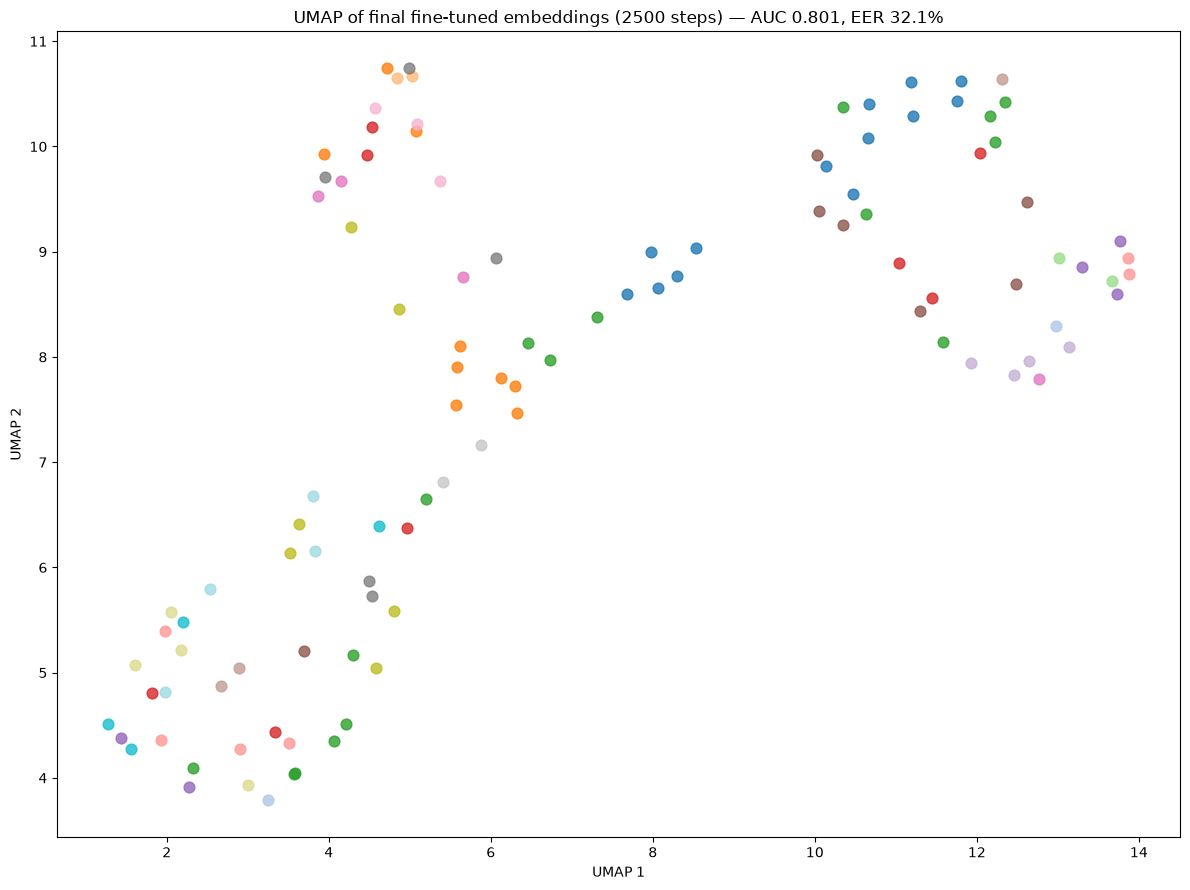

In [32]:
reducer_final = umap.UMAP(n_neighbors=10, min_dist=0.3, random_state=42)
embedding_2d_final = reducer_final.fit_transform(final_matrix)

fig, ax = plt.subplots(figsize=(12, 9))
norm_names = recordings['norm_name'].values
cantaores = pd.Series(norm_names).unique()
colors = plt.cm.tab20(np.linspace(0, 1, len(cantaores)))
color_map = dict(zip(cantaores, colors))

for cantaor in cantaores:
    mask = norm_names == cantaor
    ax.scatter(embedding_2d_final[mask, 0], embedding_2d_final[mask, 1],
               color=color_map[cantaor], s=60, alpha=0.8)

ax.set_title(f'UMAP of final fine-tuned embeddings (2500 steps) — AUC {auc_final:.3f}, EER {eer_final*100:.1f}%')
ax.set_xlabel('UMAP 1')
ax.set_ylabel('UMAP 2')
plt.tight_layout()
plt.savefig('data/processed/umap_final.png', dpi=150)
plt.show()

## Summary: from pretrained baseline to final model

| Stage | AUC | EER |
|---|---|---|
| Pretrained OpenL3 (no fine-tuning) | — (not computed; visually unstructured) | — |
| Fine-tuned, 500 steps | 0.748 | 34.0% |
| Fine-tuned, 2500 steps (first run) | 0.792 | 28.2% |
| Fine-tuned, 5000 steps | 0.789 | 33.1% |
| **Final model, 2500 steps (saved)** | **0.801** | **32.1%** |

The final model shows clear, visible clustering for several cantaores (most notably blue, orange, and green groups) that was entirely absent in the pretrained baseline. Given the very small dataset (109 recordings, 31 cantaores with 2+ recordings), this represents genuine, honestly-reported partial success - not full separation, but a measurable, reproducible improvement over the pretrained representation.

## Appendix: exploratory open-set evaluation

As discussed in the protocol decision, a full open-set evaluation isn't statistically defensible with this dataset size. This appendix runs a small, explicitly preliminary open-set experiment: a handful of cantaores are held out **entirely** from training (never seen in any triplet), and we test whether the model still produces reasonable same/different separation for their recordings, i.e., does it generalize to genuinely unseen identities, not just unseen recordings of known identities (as in the main closed-set evaluation)?

Given the very small *n* involved, results here are reported as directional evidence only, not as a robust headline metric.

In [33]:
# We choose 5 cantaores with 2 recordings for the final experiment open-set
open_set_candidates = recordings.groupby('norm_name').size()
open_set_candidates = open_set_candidates[open_set_candidates == 2].index.tolist()

rng_os = random.Random(7)
held_out_cantaores = rng_os.sample(open_set_candidates, 5)
print(f"Cantaores apartados para open-set (nunca vistos en entrenamiento): {held_out_cantaores}")

cantaores_train_os = [c for c in cantaores_train if c not in held_out_cantaores]
print(f"Cantaores restantes para entrenamiento: {len(cantaores_train_os)}")

Cantaores apartados para open-set (nunca vistos en entrenamiento): ['enriquemorente', 'bernardoloslobitos', 'lebrijano', 'pacotoronjo', 'antoniopinana']
Cantaores restantes para entrenamiento: 26


In [35]:
openset_model = ProjectionHead()
openset_optimizer = torch.optim.Adam(openset_model.parameters(), lr=1e-3)
openset_rng = random.Random(42)

n_steps_os = 2500
openset_losses = []

for step in range(n_steps_os):
    anchors, positives, negatives = sample_batch(batch_size, windows_by_cantaor, cantaores_train_os, openset_rng)

    openset_optimizer.zero_grad()
    emb_a = openset_model(anchors)
    emb_p = openset_model(positives)
    emb_n = openset_model(negatives)

    loss = triplet_loss_fn(emb_a, emb_p, emb_n)
    loss.backward()
    openset_optimizer.step()

    openset_losses.append(loss.item())

    if (step + 1) % 250 == 0:
        avg_loss = sum(openset_losses[-250:]) / 250
        print(f"Step {step + 1}/{n_steps_os} — avg loss (last 250): {avg_loss:.4f}")

print("\nModelo open-set entrenado (sin ver los 5 cantaores apartados).")

Step 250/2500 — avg loss (last 250): 0.0953
Step 500/2500 — avg loss (last 250): 0.0665
Step 750/2500 — avg loss (last 250): 0.0599
Step 1000/2500 — avg loss (last 250): 0.0612
Step 1250/2500 — avg loss (last 250): 0.0590
Step 1500/2500 — avg loss (last 250): 0.0585
Step 1750/2500 — avg loss (last 250): 0.0547
Step 2000/2500 — avg loss (last 250): 0.0501
Step 2250/2500 — avg loss (last 250): 0.0490
Step 2500/2500 — avg loss (last 250): 0.0447

Modelo open-set entrenado (sin ver los 5 cantaores apartados).


### Open-set evaluation: held-out cantaores only

We compute embeddings for the 5 held-out cantaores' recordings only, then form pairs among them exactly as in the main evaluation (same cantaor = positive, different = negative). Since these identities were never seen in training, this measures genuine generalization to new singers, the true open-set question.

In [36]:
openset_model.eval()

# Embeddings solo para los cantaores apartados (todas sus grabaciones, sin distinción train/test aquí)
held_out_recordings = recordings[recordings['norm_name'].isin(held_out_cantaores)].reset_index(drop=True)

openset_embeddings = []
with torch.no_grad():
    for _, row in held_out_recordings.iterrows():
        key = row['recording_id'].rsplit('.', 1)[0]
        windows = np.load(WINDOWS_DIR / f"{key}.npy")
        windows_tensor = torch.tensor(windows, dtype=torch.float32)
        projected = openset_model(windows_tensor)
        rec_emb = projected.mean(dim=0).numpy()
        openset_embeddings.append(rec_emb)

openset_matrix = np.stack(openset_embeddings)
print(f"Grabaciones de cantaores apartados: {len(held_out_recordings)}")

# Formar todos los pares posibles entre estas grabaciones (excluyendo comparar una consigo misma)
os_pair_distances = []
os_pair_labels = []

n = len(held_out_recordings)
for i in range(n):
    for j in range(i + 1, n):
        cant_i = held_out_recordings.loc[i, 'norm_name']
        cant_j = held_out_recordings.loc[j, 'norm_name']
        dist = 1 - np.dot(openset_matrix[i], openset_matrix[j])
        os_pair_distances.append(dist)
        os_pair_labels.append(1 if cant_i == cant_j else 0)

os_pair_distances = np.array(os_pair_distances)
os_pair_labels = np.array(os_pair_labels)

print(f"Pares totales: {len(os_pair_distances)}")
print(f"Pares positivos: {os_pair_labels.sum()}")
print(f"Pares negativos: {(os_pair_labels == 0).sum()}")

Grabaciones de cantaores apartados: 10
Pares totales: 45
Pares positivos: 5
Pares negativos: 40


In [37]:
from sklearn.metrics import roc_auc_score, roc_curve

os_similarity = -os_pair_distances

if len(np.unique(os_pair_labels)) == 2:
    os_auc = roc_auc_score(os_pair_labels, os_similarity)
    fpr_os, tpr_os, thresholds_os = roc_curve(os_pair_labels, os_similarity)
    fnr_os = 1 - tpr_os
    eer_idx_os = np.nanargmin(np.abs(fpr_os - fnr_os))
    eer_os = (fpr_os[eer_idx_os] + fnr_os[eer_idx_os]) / 2

    print(f"Open-set (5 cantaores nunca vistos) -> AUC: {os_auc:.4f}, EER: {eer_os*100:.1f}%")
else:
    print("No hay suficiente variedad de etiquetas para calcular AUC/EER.")

# Para contexto: distancia media de los 5 pares positivos vs. los 40 negativos
print(f"\nDistancia media pares positivos: {os_pair_distances[os_pair_labels==1].mean():.4f}")
print(f"Distancia media pares negativos: {os_pair_distances[os_pair_labels==0].mean():.4f}")

Open-set (5 cantaores nunca vistos) -> AUC: 0.9700, EER: 15.0%

Distancia media pares positivos: 0.1857
Distancia media pares negativos: 0.6263


### Open-set result: promising signal, not a robust metric

The open-set experiment yields AUC 0.970, EER 15.0%, numerically better than the main closed-set result (AUC 0.801, EER 32.1%). **This should not be read as "the model generalizes better to unseen cantaores than to known ones."** With only 5 positive pairs, this metric has very high variance; a single pair going differently could shift the EER by several percentage points. The result is better explained as a small-sample artifact than as genuine superior generalization.

What *is* meaningful here is the clear separation in mean distances: positive pairs average 0.186, negative pairs average 0.626 - a substantial gap suggesting the model does capture *some* transferable notion of vocal style, even for cantaores never seen during training. This is presented as encouraging directional evidence for future work with a larger held-out set, not as a validated open-set performance claim.

## Limitations and conclusions

### Dataset size
This project's central constraint throughout was dataset size: 109 recordings across 79 unique cantaores, with only 31 cantaores having 2+ reliable recordings and 16 having 3+. This shaped nearly every methodological decision - closed-set rather than open-set as the primary protocol, transfer learning (OpenL3) rather than training from scratch, window-level embeddings as a data-augmentation strategy for triplet sampling, and a small projection head (512→256→128) sized to avoid overfitting a tiny training set. Each of these choices is documented at the point it was made, rather than presented as a given.

### What the results show
The fine-tuned model (AUC 0.801, EER 32.1% on held-out closed-set pairs) demonstrates measurable, reproducible improvement over the pretrained OpenL3 baseline (both visually (UMAP clustering for several cantaores, absent in the baseline) and quantitatively). This is a genuine, if partial, signal that vocal style, not just palo, is a learnable dimension of these recordings, using standard metric-learning techniques from speaker verification adapted to cante flamenco.

### What the results don't show
An EER of 32% is far from production-grade speaker verification (typically single-digit EER with far larger datasets). Run-to-run variance (documented above) means single-run metrics should be read as indicative rather than precise. The open-set appendix, while encouraging in its distance-gap finding, is based on too few positive pairs (5) to support a robust generalization claim.

### Honest framing for future work
With more recordings per cantaor - even modest increases, given how much difference 2 vs. 1 recording already made to viable protocol design, a genuine open-set evaluation with statistical power becomes possible. Averaging metrics across multiple training runs (different seeds) would give more defensible point estimates. Fine-tuning OpenL3's own weights (rather than freezing them and training only the small head) is a natural next step if more data or more compute becomes available, though it was deliberately avoided here given the risk of overfitting with under 200 recordings total.

### Relationship to the rest of the portfolio
Where the palos classifier demonstrates classical ML on hand-crafted features for a genre-classification task, this project demonstrates representation/metric learning via transfer learning for a singer-identification task - a distinct MIR problem family, covering a genuine gap in technical breadth for a computational musicology portfolio.